In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Statistical hypothesis testing
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Set the default Matplotlib figure size
plt.rcParams["figure.figsize"] = (20, 7)

# Import Data

In [2]:
# Import display for notebook tables.
from IPython.display import display

# Load job application records from the original CSV.
applications = pd.read_csv("applications.csv")
# Load candidate profiles from the original CSV.
candidates = pd.read_csv("candidates.csv")
# Load company profiles from the original CSV.
companies = pd.read_csv("companies.csv")
# Load interview events from the original CSV.
interviews = pd.read_csv("interviews.csv")
# Load advertised jobs from the original CSV.
jobs = pd.read_csv("jobs.csv")
# Load offer decisions and acceptance dates from the original CSV.
offers = pd.read_csv("offers.csv")

# Group the six source tables for repeated audits.
datasets = {"Applications": applications, "Candidates": candidates,
            "Companies": companies, "Interviews": interviews,
            "Jobs": jobs, "Offers": offers}

# Display row and column counts for each table.
display(pd.DataFrame({name: {"rows": len(df), "columns": len(df.columns)}
                      for name, df in datasets.items()}).T)

,rows,columns
Applications,15000,7
Candidates,9000,6
Companies,320,5
Interviews,7196,5
Jobs,2000,11
Offers,938,6


# Data Preparation

Step 1 — Convert Date Columns

In [3]:
# Convert application dates
applications["applied_at"] = pd.to_datetime(applications["applied_at"])

# Convert job posting dates
jobs["posted_at"] = pd.to_datetime(jobs["posted_at"])

# Convert interview dates
interviews["scheduled_at"] = pd.to_datetime(interviews["scheduled_at"])

# Convert offer and acceptance dates
offers["offered_at"] = pd.to_datetime(offers["offered_at"])
offers["accepted_at"] = pd.to_datetime(offers["accepted_at"])

# Verify the date conversions
print(applications["applied_at"].dtype)
print(jobs["posted_at"].dtype)
print(interviews["scheduled_at"].dtype)
print(offers[["offered_at", "accepted_at"]].dtypes)

datetime64[ns]
datetime64[ns]
datetime64[ns]
offered_at     datetime64[ns]
accepted_at    datetime64[ns]
dtype: object


Step 2 — Recreate Date Validation Fields

Recreate the analytical columns from the initial investigation. Keep original timestamps unchanged. These fields document chronology, not corrected recruitment dates.

In [4]:
# Calculate the number of days between an offer and its acceptance
offers["acceptance_days"] = (
    offers["accepted_at"] - offers["offered_at"]
).dt.days

# Initially classify records as not applicable
offers["validation"] = "not_applicable"

# Identify accepted offers with valid chronological dates
offers.loc[
    (offers["accepted"] == True) &
    (offers["acceptance_days"] >= 0),
    "validation"
] = "valid_date"

# Identify accepted offers with negative acceptance durations
offers.loc[
    (offers["accepted"] == True) &
    (offers["acceptance_days"] < 0),
    "validation"
] = "chronology_exception"

# Verify the classification
print(offers["validation"].value_counts())

validation
valid_date              482
not_applicable          239
chronology_exception    217
Name: count, dtype: int64


Step 3 — Recruitment Source Standardization

In [5]:
# Define clear recruitment source labels
source_labels = {
    "job_board": "Job Board",
    "linkedin": "LinkedIn",
    "referral": "Referral",
    "outbound": "Outbound / Proactive Sourcing",
    "recruiter": "Recruiter-Sourced (Unspecified)"
}

# Create a descriptive recruitment source column
applications["Source_Label"] = applications["source"].replace(source_labels)

# Verify the original and standardized source labels
display(
    applications[["source", "Source_Label"]]
    .drop_duplicates()
    .sort_values("source")
)

,source,Source_Label
0,job_board,Job Board
1,linkedin,LinkedIn
8,outbound,Outbound / Proactive Sourcing
4,recruiter,Recruiter-Sourced (Unspecified)
13,referral,Referral


## Statistical Analysis — Research Questions and Hypotheses

This notebook extends the descriptive findings from `Analysis.ipynb` through three inferential statistical investigations.

The objectives are to evaluate whether observed recruitment patterns are statistically associated with recruitment source, candidate experience, and relative salary position.

### Planned Investigations

1. **H1 — Recruitment Source Effectiveness:** Do offer rates differ across recruitment sources?
2. **H2 — Candidate Experience:** Do applicants receiving offers differ in years of experience from applicants who do not receive offers?
3. **H3 — Salary Position and Acceptance:** Is the relative position of an offered salary within the advertised range associated with offer acceptance?

### Statistical Approach

- Use a significance level of **α = 0.05** as a conventional threshold, not as the sole basis for conclusions.
- Report appropriate effect sizes and confidence intervals where possible.
- Evaluate statistical assumptions before interpreting test results.
- Distinguish statistical significance from practical business importance.
- Retain original datasets and document any analytical exclusions.

**Important limitation:** The dataset is synthetic. Statistical relationships identified in this analysis describe patterns within the generated records and should not automatically be generalized to real recruitment populations. Applications may also share candidates, jobs, or companies, which must be considered when evaluating independence assumptions.

# H1 — Recruitment Source Effectiveness

- **What:** Determine whether offer conversion rates differ significantly across recruitment sources.
- **Why:** Our descriptive analysis (Q2) showed differences in offer rates, but we need to assess whether these differences are statistically significant.
- **How:** Use a **Chi-square test of independence** to examine the association between recruitment source and offer outcome, followed by **Cramér's V** to measure the strength of that association.
- **Business Importance:** Help recruitment teams evaluate sourcing effectiveness, improve recruitment strategies, and make evidence-based decisions about allocating sourcing resources.

Step 1 — Statistical Hypotheses

- **Null Hypothesis (H₀):** Recruitment source and offer outcome are independent. Offer conversion rates do not differ systematically across recruitment sources.
- **Alternative Hypothesis (H₁):** Recruitment source and offer outcome are associated. At least one recruitment source has a different offer conversion rate.
- **Significance Level (α):** 0.05 (5%).
- **Statistical Test:** Chi-square Test of Independence.
- **Effect Size:** Cramér's V, to measure the strength of the association.

Step 2: Create the Contingency Table

In [6]:
# Identify applications that received an offer
offer_ids = offers["application_id"]

# Create a separate dataframe for our H1 statistical analysis
h1_analysis = applications[["application_id", "Source_Label"]].copy()

# Identify whether each application received an offer
h1_analysis["Received_Offer"] = h1_analysis["application_id"].isin(offer_ids)

# Create a contingency table of recruitment source and offer outcome
contingency_table = pd.crosstab(
    h1_analysis["Source_Label"],
    h1_analysis["Received_Offer"]
)

# Rename the columns for easier interpretation
contingency_table.columns = ["No Offer", "Received Offer"]

# Display the contingency table
display(contingency_table)

# Verify that all applications have been included
print("Total applications:", contingency_table.to_numpy().sum())

,No Offer,Received Offer
Source_Label,,
Job Board,6635,459
LinkedIn,2489,159
Outbound / Proactive Sourcing,1249,84
Recruiter-Sourced (Unspecified),1147,84
Referral,2542,152


Total applications: 15000


Step 3: Chi-square Test of Independence

The Chi-square test compares two things:
- Observed frequencies: The actual counts in our contingency table.
- Expected frequencies: The counts we would expect if recruitment source and offer outcome were independent.

In [7]:
# Import the Chi-square test
from scipy.stats import chi2_contingency

# Perform the Chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Display the statistical results
print(f"Chi-square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

# Convert expected frequencies into a dataframe
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

# Display expected frequencies
print("\nExpected Frequencies:")
display(expected_table.round(2))

Chi-square Statistic: 3.2540
P-value: 0.5163
Degrees of Freedom: 4

Expected Frequencies:


,No Offer,Received Offer
Source_Label,,
Job Board,6650.39,443.61
LinkedIn,2482.41,165.59
Outbound / Proactive Sourcing,1249.64,83.36
Recruiter-Sourced (Unspecified),1154.02,76.98
Referral,2525.54,168.46


What do these numbers mean?
- Chi-square statistic (3.2540): Measures the combined discrepancy between observed and expected frequencies.
- P-value (0.5163): If recruitment source and offer outcome were independent, a Chi-square statistic at least this large would not be particularly unusual.
- Significance level (0.05): Since 0.5163 > 0.05, we fail to reject our null hypothesis.
- Statistical conclusion: We have insufficient evidence to conclude that recruitment source and offer outcome are associated in this synthetic dataset.

Step 4: Calculate Cramér's V

-Our Chi-square test assesses evidence of an association.

-Cramér's V measures how strong that association is, on a scale from 0 (no association) to 1 (strongest possible association).

In [8]:
# Import NumPy for the square root calculation
import numpy as np

# Calculate the total number of applications
n = contingency_table.to_numpy().sum()

# Determine the number of rows and columns
rows, cols = contingency_table.shape

# Calculate Cramér's V
cramers_v = np.sqrt(chi2 / (n * min(rows - 1, cols - 1)))

# Display the effect size
print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.0147


Step 4: Interpreting Cramér's V

Putting H1 together

<li>Statistical measure	Result	Interpretation
<li>Chi-square statistic	3.2540	Small overall discrepancy between observed and expected counts
<li>P-value	0.5163	Not statistically significant at α = 0.05
<li>Cramér's V	0.0147	Negligible association
<li>Applications	15,000	Five recruitment sources examined

### H1 — Statistical Findings and Business Recommendations

#### Key Findings

- **Chi-square test:** Among 15,000 applications (938 offers), recruitment source and offer outcome showed no statistically significant association: **χ²(4) = 3.2540, p = 0.5163**.
- **Effect size:** **Cramér's V = 0.0147**, indicating a negligible association despite observed source offer rates of **5.64%–6.82%**.
- **Assumptions:** All expected frequencies exceeded 5; however, repeated candidates and shared jobs may affect observation independence.

#### Business Insights & Recommendations

- **Sourcing decisions:** Do not prioritise or defund a source based solely on these small differences in offer rates; consider cost, candidate suitability, timelines and acceptance outcomes.
- **Data definitions:** Clarify what `outbound` and `recruiter` mean before making channel-specific decisions.

#### Analytical Limitations

- **Synthetic and observational data:** Findings may not reflect real recruitment, and the test does not control for role, seniority or employer differences.
- **Interpretation:** A non-significant result does not prove equal source effectiveness; repeated applications may also challenge the test's independence assumption.

#### Overall Business Conclusion

- **No statistically significant association was detected between recruitment source and offer outcome.** Source performance should be assessed using broader recruitment and cost measures.


# H2 — Candidate Experience and Offer Outcome

- **What:** Determine whether applicants receiving job offers differ in years of experience from applicants without recorded offers.
- **Why:** Our descriptive analysis (Q5) showed very similar experience distributions between the two groups. We now want to evaluate whether the observed differences are statistically significant.
- **How:** Compare years of experience using **Welch's t-test or Mann–Whitney U test**, depending on the data distributions and statistical assumptions.
- **Business Importance:** Help recruitment teams evaluate the relationship between experience and selection outcomes, support evidence-based screening practices, and identify opportunities to improve candidate assessment.

Step 1 — Define our hypotheses

#### Statistical Hypotheses

- **Null Hypothesis (H₀):** There is no difference in years of experience between applicants receiving offers and those without recorded offers.
- **Alternative Hypothesis (H₁):** Years of experience differ between applicants receiving offers and those without recorded offers.
- **Significance Level (α):** 0.05.
- **Statistical Test:** Welch's t-test or Mann–Whitney U test, selected after examining the data and assumptions.
- **Effect Size:** An appropriate measure to quantify the magnitude of any observed difference.

Step 2: Prepare our experience comparison groups is next.

In [9]:
"""Our objective is to create two groups:
- Received Offer: Applications that resulted in a job offer.
- No Offer: Applications without a recorded offer."""

# Select the application and candidate IDs
h2_analysis = applications[["application_id", "candidate_id"]].copy()

# Add each applicant's years of experience
h2_analysis = h2_analysis.merge(
    candidates[["candidate_id", "years_experience"]],
    on="candidate_id",
    how="left"
)

# Identify applications that received an offer
h2_analysis["Received_Offer"] = h2_analysis["application_id"].isin(
    offers["application_id"]
)

# Separate years of experience into two groups
experience_offer = h2_analysis.loc[
    h2_analysis["Received_Offer"] == True,
    "years_experience"
].dropna()

experience_no_offer = h2_analysis.loc[
    h2_analysis["Received_Offer"] == False,
    "years_experience"
].dropna()

# Verify our data
print("Total applications:", len(h2_analysis))
print("Missing experience values:", h2_analysis["years_experience"].isna().sum())
print("Applications with offers:", len(experience_offer))
print("Applications without offers:", len(experience_no_offer))

# Compare basic descriptive statistics
print("\nApplicants receiving offers:")
display(experience_offer.describe().round(2))

print("\nApplicants without recorded offers:")
display(experience_no_offer.describe().round(2))

Total applications: 15000
Missing experience values: 0
Applications with offers: 938
Applications without offers: 14062

Applicants receiving offers:


count   938.00
mean      8.38
std       5.30
min       0.00
25%       4.00
50%       8.00
75%      13.00
max      17.00
Name: years_experience, dtype: float64


Applicants without recorded offers:


count   14062.00
mean        8.54
std         5.21
min         0.00
25%         4.00
50%         9.00
75%        13.00
max        17.00
Name: years_experience, dtype: float64

Three observations:
- Mean difference: Applicants receiving offers averaged approximately 0.16 fewer years of experience.
- Similar variability: Both groups have standard deviations of approximately 5.2 years.
- Substantial overlap: Both groups share the same overall experience range and interquartile range (4–13 years).

Step 3: Check Repeated Candidates

In [10]:
"""Our dataset contains 15,000 applications but only 9,000 candidates overall. That means some candidates may have submitted multiple applications.

Why does this matter?
*   Both Welch's t-test and Mann-Whitney U generally assume independent observations.
*   If the same candidate appears several times, their years of experience are repeated. 
        Treating those applications as independent observations could exaggerate the amount of statistical information available."""

# Count the number of unique candidates in our H2 analysis
unique_candidates = h2_analysis["candidate_id"].nunique()

# Identify candidates who submitted multiple applications
application_counts = h2_analysis["candidate_id"].value_counts()

# Count candidates with more than one application
repeat_candidates = (application_counts > 1).sum()

# Find the highest number of applications from one candidate
max_applications = application_counts.max()

# Display our findings
print("Total applications:", len(h2_analysis))
print("Unique candidates:", unique_candidates)
print("Candidates with multiple applications:", repeat_candidates)
print("Maximum applications from one candidate:", max_applications)

Total applications: 15000
Unique candidates: 7324
Candidates with multiple applications: 4434
Maximum applications from one candidate: 9


Step 4: Create Candidate-Level Comparison Groups

In [11]:
# Identify candidates who received at least one offer
candidate_offers = h2_analysis.groupby("candidate_id")["Received_Offer"].any()

# Create a separate candidate-level dataframe
h2_candidates = candidates[
    ["candidate_id", "years_experience"]
].copy()

# Keep only candidates who submitted an application
h2_candidates = h2_candidates[
    h2_candidates["candidate_id"].isin(h2_analysis["candidate_id"])
].copy()

# Add the candidate-level offer outcome
h2_candidates = h2_candidates.merge(
    candidate_offers.rename("Received_Offer"),
    on="candidate_id",
    how="left"
)

# Separate candidates into two experience groups
experience_offer = h2_candidates.loc[
    h2_candidates["Received_Offer"] == True,
    "years_experience"
]

experience_no_offer = h2_candidates.loc[
    h2_candidates["Received_Offer"] == False,
    "years_experience"
]

# Verify the candidate-level data
print("Total candidates:", len(h2_candidates))
print("Duplicate candidate IDs:", h2_candidates["candidate_id"].duplicated().sum())
print("Missing experience values:", h2_candidates["years_experience"].isna().sum())
print("Candidates receiving offers:", len(experience_offer))
print("Candidates without offers:", len(experience_no_offer))

# Compare descriptive statistics
print("\nCandidates receiving offers:")
display(experience_offer.describe().round(2))

print("\nCandidates without offers:")
display(experience_no_offer.describe().round(2))

Total candidates: 7324
Duplicate candidate IDs: 0
Missing experience values: 0
Candidates receiving offers: 898
Candidates without offers: 6426

Candidates receiving offers:


count   898.00
mean      8.33
std       5.31
min       0.00
25%       4.00
50%       8.00
75%      13.00
max      17.00
Name: years_experience, dtype: float64


Candidates without offers:


count   6426.00
mean       8.53
std        5.21
min        0.00
25%        4.00
50%        9.00
75%       13.00
max       17.00
Name: years_experience, dtype: float64

In [12]:
# Count unique candidates in the original applications dataframe
applications["candidate_id"].nunique()

7324

In [13]:
applications["candidate_id"].duplicated().sum()

7676

Step 5: Welch's t-test

<li>What: Compare the average years of experience between candidates who received at least one offer and those who received none.

<li>Why Welch's t-test? It compares two group means without assuming equal population variances.

<li>H₀: The two groups have equal mean years of experience.

<li>H₁: The two groups have different mean years of experience.

<li>Significance level: α = 0.05.

In [14]:
# Import Welch's t-test
from scipy.stats import ttest_ind

"""What will these results tell us?
- T-statistic: Measures the difference between the two group means relative to the estimated uncertainty. 
    A negative value indicates that the offer group's mean is lower.
- P-value: Helps us assess whether the observed difference provides sufficient evidence against H₀."""


# Perform Welch's t-test on the two candidate groups
t_stat, p_value = ttest_ind(
    experience_offer,
    experience_no_offer,
    equal_var=False
)

# Display the statistical results
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: -1.0999
P-value: 0.2716


Key observations
- T-statistic (-1.0999): The negative sign indicates that candidates receiving offers had slightly less experience on average.
- P-value (0.2716): Since 0.2716 > 0.05, the difference is not statistically significant.
- Conclusion: We do not have sufficient statistical evidence that average years of experience differ between candidates receiving offers and those without offers.

Step 6: Calculate Cohen's d

In [15]:
# Import NumPy for numerical calculations
import numpy as np

# Calculate sample sizes for both groups
n1 = len(experience_offer)
n2 = len(experience_no_offer)

# Calculate the average experience for each group
mean1 = experience_offer.mean()
mean2 = experience_no_offer.mean()

# Calculate the sample variances
var1 = experience_offer.var(ddof=1)
var2 = experience_no_offer.var(ddof=1)

# Calculate the pooled standard deviation for Cohen's d
pooled_std = np.sqrt(
    ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
)

# Calculate Cohen's d
cohens_d = (mean1 - mean2) / pooled_std

# Display the effect size
print(f"Cohen's d: {cohens_d:.4f}")

Cohen's d: -0.0398


What does this mean for recruitment?
- We found no statistically significant difference in average experience between the two candidate groups.
- The observed difference is extremely small relative to the variation in experience.
- Total years of experience alone does not meaningfully distinguish these two groups in our synthetic dataset.
- This does not establish that experience is unimportant for individual job requirements.

Step 7: Calculate the 95% Confidence Interval

In [16]:
# Import the t-distribution from SciPy
from scipy.stats import t

# Calculate the difference between group means
mean_difference = mean1 - mean2

# Calculate the standard error using separate group variances
standard_error = np.sqrt(var1 / n1 + var2 / n2)

# Calculate Welch-Satterthwaite degrees of freedom
degrees_freedom = (var1 / n1 + var2 / n2)**2 / (
    (var1 / n1)**2 / (n1 - 1)
    + (var2 / n2)**2 / (n2 - 1)
)

# Obtain the critical t-value for a 95% confidence interval
t_critical = t.ppf(0.975, degrees_freedom)

# Calculate the lower and upper confidence limits
ci_lower = mean_difference - t_critical * standard_error
ci_upper = mean_difference + t_critical * standard_error

# Display the results
print(f"Mean Difference: {mean_difference:.4f} years")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}] years")

Mean Difference: -0.2077 years
95% Confidence Interval: [-0.5781, 0.1628] years


What does this tell us?
- Point estimate: Candidates receiving offers averaged approximately 0.21 fewer years of experience.
- Lower limit (−0.5781): The population mean difference could plausibly favour the no-offer group by approximately 0.58 years.
- Upper limit (+0.1628): The mean difference could also plausibly favour the offer group by approximately 0.16 years.
- Zero falls inside the interval: This agrees with our non-significant Welch's t-test result (p = 0.2716).
- Practical importance: Even the estimated range of differences is small relative to the roughly 5.2-year standard deviations of experience.

![H2 Complete statistical Tests Results.png](<attachment:H2 Complete statistical Tests Results.png>)
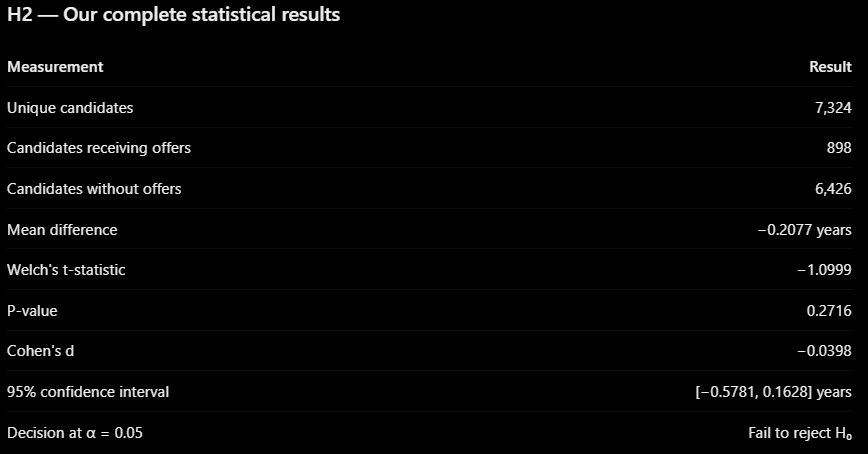

### H2 — Statistical Findings and Business Recommendations

#### Key Findings

- **Candidate-level comparison:** Of 7,324 unique applicants, **898 received at least one offer** and **6,426 received none**; each candidate was counted once.
- **Mean experience:** **8.33 years** for candidates with offers versus **8.53 years** without; the difference was **−0.2077 years**.
- **Statistical result:** Welch's t-test **t = −1.0999, p = 0.2716**; **Cohen's d = −0.0398**; **95% CI [−0.5781, 0.1628] years**. The difference was not statistically significant and its estimated effect was negligible.

#### Business Insights & Recommendations

- **Selection practices:** Assess relevant experience, technical competencies and job requirements together; total experience alone did not distinguish the two candidate groups meaningfully here.
- **Compensation distinction:** Experience may still inform established salary scales. This analysis examines **offer selection**, not how salary levels are determined.

#### Analytical Limitations

- **Synthetic and incomplete measures:** Total experience does not establish job-specific relevance; role, employer and qualifications were not controlled for.
- **Candidate-level outcome:** Receiving at least one offer depends partly on the number of applications submitted, which varied by candidate.

#### Overall Business Conclusion

- **No statistically significant difference in mean experience was detected** between candidates with and without offers; these results alone do not justify changes to experience requirements.


# H3 — Salary Position and Offer Acceptance

Step 1 — Research Objective

- **What:** Determine whether an offer's position within the advertised salary range is associated with the likelihood of acceptance.
- **Why:** Our descriptive analysis (Q6) revealed acceptance rates between **71.55% and 76.39%** across salary-position bands, without a consistent upward trend.
- **How:** Use **logistic regression** to examine the relationship between relative salary position and offer acceptance, while considering relevant job characteristics.
- **Business Importance:** Help recruitment teams understand whether positioning offers higher within advertised salary ranges is associated with improved acceptance, supporting evidence-based compensation and offer strategies.

Step 2 — Statistical Hypotheses

#### Statistical Hypotheses

- **Null Hypothesis (H₀):** Relative salary position is not associated with offer acceptance, after accounting for included job characteristics.
- **Alternative Hypothesis (H₁):** Relative salary position is associated with offer acceptance, after accounting for included job characteristics.
- **Significance Level (α):** 0.05.
- **Statistical Method:** Binary logistic regression.
- **Dependent Variable:** Offer acceptance (`accepted`: Yes / No).
- **Primary Independent Variable:** Relative salary position within the advertised salary range.
- **Additional Variables:** Job role family and seniority level, where appropriate.
- **Effect Size:** Odds ratio, representing the change in acceptance odds associated with a specified increase in salary position.

Step 3: Prepare Our Salary Analysis DataFrame

In [17]:
# Connect each offer to its application and job
h3_analysis = offers.merge(
    applications[["application_id", "job_id", "candidate_id"]],
    on="application_id",
    how="left"
)

# Add advertised salary ranges and job characteristics from Jobs table
h3_analysis = h3_analysis.merge(
    jobs[["job_id", "salary_low", "salary_high", "role_family", "level"]],
    on="job_id",
    how="left"
)

# Calculate the width of each advertised salary range by creating a new column Salary_Range
h3_analysis["Salary_Range"] = (
    h3_analysis["salary_high"] - h3_analysis["salary_low"]
)

# Calculate the relative salary position as a percentage
h3_analysis["Salary_Position"] = (
    (h3_analysis["base_salary"] - h3_analysis["salary_low"])
    / h3_analysis["Salary_Range"] * 100
)

# Convert offer acceptance into a numeric outcome for logistic regression
h3_analysis["Accepted_Outcome"] = h3_analysis["accepted"].astype(int)

# Verify our analytical dataset
print("Total offers:", len(h3_analysis))
print("Accepted offers:", h3_analysis["Accepted_Outcome"].sum())
print("Missing salary positions:", h3_analysis["Salary_Position"].isna().sum())
print("Invalid salary ranges:", (h3_analysis["Salary_Range"] <= 0).sum())
print("Offers outside advertised salary ranges:",
      (~h3_analysis["Salary_Position"].between(0, 100)).sum())
print("Unique candidates:", h3_analysis["candidate_id"].nunique())

# Preview the relevant columns
display(
    h3_analysis[
        ["application_id", "role_family", "level",
         "Salary_Position", "Accepted_Outcome"]
    ].head()
)

Total offers: 938
Accepted offers: 699
Missing salary positions: 0
Invalid salary ranges: 0
Offers outside advertised salary ranges: 0
Unique candidates: 898


,application_id,role_family,level,Salary_Position,Accepted_Outcome
0,8,data,mid,13.04,1
1,13,data,lead,25.82,1
2,25,product,senior,60.86,0
3,29,engineering,junior,67.41,1
4,30,sales,senior,63.35,1


H3 — Step 4: Run Our First Logistic Regression

In [18]:
# Import statsmodels for logistic regression
import statsmodels.formula.api as smf

# Fit a logistic regression model using salary position
# Clustered standard errors account for multiple offers to the same candidate
h3_model1 = smf.logit(
    formula="Accepted_Outcome ~ Salary_Position",
    data=h3_analysis
).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": h3_analysis["candidate_id"]}
)

# Display the model results
print(h3_model1.summary())

                           Logit Regression Results                           
Dep. Variable:       Accepted_Outcome   No. Observations:                  938
Model:                          Logit   Df Residuals:                      936
Method:                           MLE   Df Model:                            1
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:               0.0007336
Time:                        14:47:53   Log-Likelihood:                -531.97
converged:                       True   LL-Null:                       -532.36
Covariance Type:              cluster   LLR p-value:                    0.3768
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.9593      0.150      6.415      0.000       0.666       1.252
Salary_Position     0.0023      0.003      0.873      0.382      -0.003       0.007


What does this mean?
- Positive coefficient (+0.0023): Offers positioned higher within their advertised salary ranges had slightly higher estimated log-odds of acceptance.
- P-value (0.382): Since 0.382 > 0.05, we do not have sufficient evidence of a relationship between salary position and acceptance in this model.
- Confidence interval: The interval includes zero, meaning the results are compatible with either a small negative or a small positive association.
- Pseudo R²: Salary position alone provides very little explanatory improvement over a model without salary position.

**Important**: The positive coefficient does not establish that increasing an offer causes candidates to accept it.

Step 5: Calculate the Odds Ratio

In [19]:
# Import NumPy for the exponential calculation
import numpy as np

# Extract the salary position coefficient
salary_coefficient = h3_model1.params["Salary_Position"]

# Extract the 95% confidence interval
salary_ci = h3_model1.conf_int().loc["Salary_Position"]

# Calculate the odds ratio for a 10-percentage-point increase
odds_ratio_10 = np.exp(salary_coefficient * 10)

# Calculate the corresponding confidence interval
or_lower = np.exp(salary_ci.iloc[0] * 10)
or_upper = np.exp(salary_ci.iloc[1] * 10)

# Display the results
print(f"Odds Ratio (10 percentage points): {odds_ratio_10:.4f}")
print(f"95% Confidence Interval: [{or_lower:.4f}, {or_upper:.4f}]")

Odds Ratio (10 percentage points): 1.0232
95% Confidence Interval: [0.9719, 1.0772]


What does this tell us?
- Odds Ratio = 1.0232: A 10-percentage-point increase in salary position is associated with approximately 2.32% higher estimated odds of offer acceptance.
- Confidence Interval: The plausible range extends from approximately 2.81% lower odds to 7.72% higher odds, under our model assumptions.
- Statistical Significance: The interval includes 1, consistent with our non-significant p-value of 0.382.
- Business Interpretation: We have insufficient evidence that moving an offer higher within its advertised salary range is associated with increased acceptance odds.

Step 6: Account for Role Family and Seniority

In [20]:
# Fit logistic regression with salary position, role family and job level
# Clustered standard errors account for multiple offers to the same candidate
h3_model2 = smf.logit(
    formula="Accepted_Outcome ~ Salary_Position + C(role_family) + C(level)",
    data=h3_analysis
).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": h3_analysis["candidate_id"]}
)

# Display the adjusted regression results
print(h3_model2.summary())

                           Logit Regression Results                           
Dep. Variable:       Accepted_Outcome   No. Observations:                  938
Model:                          Logit   Df Residuals:                      928
Method:                           MLE   Df Model:                            9
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                0.009938
Time:                        14:47:53   Log-Likelihood:                -527.07
converged:                       True   LL-Null:                       -532.36
Covariance Type:              cluster   LLR p-value:                    0.3055
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         0.8510      0.478      1.780      0.075      -0.086       1.788
C(role_family)[T.data]            0.3819      0.467      0.818      0.413 

What have we learned?
- Salary position: The coefficient remains slightly positive, but it is not statistically significant (p = 0.459).
- Role family: None of the individual role-family coefficients is statistically significant at α = 0.05.
- Seniority level: None of the individual seniority coefficients is statistically significant at α = 0.05.
- Pseudo R²: The adjusted model shows a modest improvement in fit, but its explanatory value remains low.
- Overall model: The likelihood-ratio p-value is 0.3055, providing insufficient evidence that this model improves fit over the intercept-only model.

Step 7: Calculate the Adjusted Odds Ratio

In [21]:
# Extract the adjusted salary position coefficient
adjusted_coefficient = h3_model2.params["Salary_Position"]

# Extract its 95% confidence interval
adjusted_ci = h3_model2.conf_int().loc["Salary_Position"]

# Calculate the adjusted odds ratio for a 10-percentage-point increase
adjusted_or_10 = np.exp(adjusted_coefficient * 10)

# Calculate the confidence interval for the adjusted odds ratio
adjusted_or_lower = np.exp(adjusted_ci.iloc[0] * 10)
adjusted_or_upper = np.exp(adjusted_ci.iloc[1] * 10)

# Display the results
print(f"Adjusted Odds Ratio (10 percentage points): {adjusted_or_10:.4f}")
print(f"95% Confidence Interval: [{adjusted_or_lower:.4f}, {adjusted_or_upper:.4f}]")

Adjusted Odds Ratio (10 percentage points): 1.0199
95% Confidence Interval: [0.9680, 1.0747]


What does our adjusted odds ratio mean?
- Adjusted odds ratio = 1.0199: A 10-percentage-point increase in salary position is associated with approximately 1.99% higher estimated odds of acceptance, holding role family and job seniority constant.
- 95% confidence interval = [0.9680, 1.0747]: The interval is compatible with approximately 3.20% lower odds to 7.47% higher odds.
- P-value = 0.459: We fail to reject our null hypothesis at α = 0.05.
- Model comparison: Accounting for role family and seniority barely changed the estimated salary-position association.

Step 8: Create Our Final Statistical Summary

In [22]:
# Create a summary table comparing both logistic regression models
h3_summary = pd.DataFrame({
    "Model": ["Unadjusted", "Adjusted"],
    "Odds Ratio (10 pp)": [odds_ratio_10, adjusted_or_10],
    "CI Lower": [or_lower, adjusted_or_lower],
    "CI Upper": [or_upper, adjusted_or_upper],
    "P-value": [
        h3_model1.pvalues["Salary_Position"],
        h3_model2.pvalues["Salary_Position"]
    ]
})

# Display the results with four decimal places
display(h3_summary.round(4))

,Model,Odds Ratio (10 pp),CI Lower,CI Upper,P-value
0,Unadjusted,1.02,0.97,1.08,0.38
1,Adjusted,1.02,0.97,1.07,0.46


**Our final interpretation**: We found insufficient statistical evidence that an offer's relative position within its advertised salary range is associated with acceptance, either before or after adjusting for role family and seniority.

That doesn't mean salary is unimportant. It means our analysis hasn't identified a statistically significant relationship for this particular salary-position measure.

### H3 — Statistical Findings and Business Recommendations

#### Key Findings

- **Sample:** **938 offers** to **898 candidates**, including **699 accepted offers (74.52%)**; salary positions were valid and within advertised ranges.
- **Unadjusted model:** For a **10-percentage-point** increase in salary position, **OR = 1.0232** (95% CI **0.9719–1.0772**, **p = 0.382**).
- **Adjusted model:** Controlling for role family and seniority, **OR = 1.0199** (95% CI **0.9680–1.0747**, **p = 0.459**). Neither model identified a statistically significant salary-position association; candidate-clustered standard errors accounted for repeated offers.

#### Business Insights & Recommendations

- **Offer strategy:** Do not assume placing an offer higher within its advertised range will increase acceptance; the evidence here is insufficient.
- **Compensation intelligence:** Combine internal salary bands with external market benchmarks, candidate expectations and reasons for declined offers.

#### Analytical Limitations

- **Synthetic and incomplete data:** Relative salary position is not external market competitiveness; competing offers, expectations and other influences are unavailable or unmeasured.
- **Model scope:** Only a linear salary-position association in log-odds was examined; adjustment for role and seniority does not establish causation or remove all confounding.

#### Overall Business Conclusion

- **Relative salary position was not a statistically significant predictor of offer acceptance** in either logistic model; compensation decisions require additional market and candidate information.
